# Evaluating the power control

> How well the learned power control predicts the channel and reaches a target reliability on layouts it has not seen, against C3-WM's predictor and others, what the agents then receive, and the same through a comm-core network.

In [ ]:
#| default_exp comm.evaluation

In [ ]:
#| hide
from nbdev.showdoc import *

Everything is measured on the test layouts, which neither the predictors nor their calibration saw:

1. **The prediction** (`prediction_errors`): the error of `ĝ` in dB (bias and spread), and its coverage (the share of
   transmissions whose gain is at least `ĝ`; a 5% quantile should cover about 95%).
2. **Against other predictors** (`baselines`), fit on the same training layouts: C3-WM's (linear in `|h|²` over the
   last gains, eqs. 24–25), the same fit in dB, a quantile model of the history alone (no geometry), and perfect CSI.
3. **Reliability against power** (`operating_points`, `frontier`): for each target, the margin and threshold chosen
   on the calibration layouts, and what they give on the test layouts; and the best reliability each predictor
   reaches for each power (a frontier: margins tried on the test layouts themselves, an upper bound). Perfect CSI is
   the reference as defined: exactly `Γ` on every servable transmission, nothing else sent. (Least power for a target
   reliability allows withholding the most expensive transmissions, so a calibrated policy can spend less than perfect
   CSI at a target below 100%.)
4. **What the agents receive** (`received`): the share of the servable messages arriving without a bit error, and the
   share of wrong tokens in those sent, for uncoded BPSK at the SNR each transmission gets.
5. **Through a network** (`simulate_network`): `LearnedChannelInversion` in a comm-core `LinkLevelChannel` (every bit)
   on the test layouts' trajectories, against the analysis.
6. **At other target SNRs** (`snr_sweep`): 3–4 again for each `Γ`, the predictors unchanged (they predict the gain,
   which doesn't depend on `Γ`), `κ` and `τ` chosen again on the calibration layouts.

`evaluate_power_control` runs them all but the network (the `evaluate` stage of `mains/comm_power.py` runs that too).

In [ ]:
#| export
from __future__ import annotations

import math
from dataclasses import replace
from pathlib import Path

import numpy as np

from c3jepa_wm.comm.channel_data import ChannelTable, db, episode_fading, table_path
from c3jepa_wm.comm.power_control import Budget, LearnedChannelInversion, TAUS_DB, calibrate, evaluate, fit_predictor, outcome, predict_gain

## The predictors

In [ ]:
#| export
def past_gains(data: dict, history: int) -> np.ndarray:
    "The past gains |h|² of each sample (most recent first), from its features."
    return 10 ** (data['X'][:, 3:3 + history] / 10)

def baselines(train: dict, history: int, quantile: float = 0.05, max_iter: int = 400) -> dict:
    "name -> predict(dataset) -> ĝ: C3-WM's predictor (in |h|², and in dB), a history-only quantile model, and perfect CSI; fit on `train`."
    from comm_core import fit_gain_predictor
    sequences = [np.r_[p[::-1], g] for p, g in zip(past_gains(train, history), train['gain'])]
    psi, psi_db = fit_gain_predictor(sequences, history=history), fit_gain_predictor(sequences, history=history, domain='db')
    hist = lambda d: d['X'][:, 3:]                                         # past gains (dB) and moves, no geometry
    history_only = fit_predictor(hist(train), train['gain'], quantile, max_iter)
    return {
        "C3-WM's (linear in |h|²)": lambda d: np.array([max(psi(p), 0.0) for p in past_gains(d, history)]),
        "C3-WM's, in dB": lambda d: np.array([psi_db(p) for p in past_gains(d, history)]),
        'history quantile': lambda d: 10 ** (history_only.predict(hist(d)) / 10),
        'perfect CSI': lambda d: d['gain'].copy(),
    }

def prediction_errors(estimate: np.ndarray, gain: np.ndarray) -> dict:
    "The error of ĝ in dB (mean: bias, std: spread), and the share of transmissions whose gain is at least ĝ (coverage)."
    error = db(estimate) - db(gain)
    return dict(bias_db=float(error.mean()), spread_db=float(error.std()), coverage=float((gain >= estimate * (1 - 1e-9)).mean()))

## Reliability and power

In [ ]:
#| export
def operating_points(cal: tuple, test: tuple, g_min: float, targets=(0.9, 0.95, 0.99), taus_db=TAUS_DB, slack: float = 0.0) -> dict:
    """For each target: the margin and threshold chosen on the calibration layouts (`cal` = (ĝ, gain)), and the
    reliability, power and withheld share they give on the test layouts (`test` = (ĝ, gain))."""
    out = {}
    for target in targets:
        chosen = calibrate(*cal, g_min, target + slack, taus_db=taus_db)
        out[target] = dict(evaluate(*test, g_min, chosen['margin_db'], chosen['tau_db']), margin_db=chosen['margin_db'],
                           tau_db=chosen['tau_db'], met_on_calibration=chosen['met'])
    return out

def frontier(estimate: np.ndarray, gain: np.ndarray, g_min: float, taus_db=(0.0, math.inf)) -> tuple:
    "(power, reliability): the most reliable outcome for each power over margins and thresholds tried on these transmissions (an upper bound)."
    points = np.concatenate([np.c_[o['power'], o['reliability']] for o in (outcome(estimate, gain, g_min, t) for t in taus_db)])
    points = points[np.argsort(points[:, 0])]
    return points[:, 0], np.maximum.accumulate(points[:, 1])

## What the agents receive

In [ ]:
#| export
def transmissions(estimate: np.ndarray, g_min: float, margin_db: float, tau_db: float) -> tuple:
    "(power in units of Γσ², sent) of each transmission, as the power control decides."
    rho = 10 ** (margin_db / 10) / np.maximum(estimate, 1e-30)
    sent = rho <= 10 ** (tau_db / 10) / g_min if math.isfinite(tau_db) else np.ones(len(rho), bool)
    return np.where(sent, np.minimum(rho, 1 / g_min), 0.0), sent

def received(estimate, gain, g_min: float, margin_db: float, tau_db: float, snr_target_db: float,
             message_bits: int = 392, bits_per_token: int = 8) -> dict:
    """Uncoded BPSK at the SNR each transmission gets (a bit is wrong with probability Q(√(2 SNR))): the share of the
    servable messages arriving without an error, and the share of wrong tokens in the servable messages sent."""
    power, sent = transmissions(estimate, g_min, margin_db, tau_db)
    snr = 10 ** (snr_target_db / 10) * power * gain
    ber = 0.5 * np.vectorize(math.erfc)(np.sqrt(snr))
    servable = gain >= g_min
    clean = np.where(sent, (1 - ber) ** message_bits, 0.0)[servable].mean()
    wrong = (1 - (1 - ber[sent & servable]) ** bits_per_token).mean() if (sent & servable).any() else float('nan')
    return dict(error_free=float(clean), wrong_tokens=float(wrong))

## Through a network

`TableFading` gives comm-core the channel of a layout's table (full or pair cache) between the nodes' cells, times a
fading factor per pair that the simulation sets at every step. `simulate_network` runs `LearnedChannelInversion`
through a `LinkLevelChannel` on the test layouts' recorded trajectories, every agent sending its tokens to every
other at every step, with the fading drawn exactly as `build_dataset` draws it (`episode_fading`, the same seeds): the
network sees the same channels as the analysis, so the two must agree, up to the bits' random errors.

In [ ]:
#| export
from comm_core import Fading

class TableFading(Fading):
    "The channel between the nodes' cells from a `ChannelTable`, times a fading factor |g|² per pair of nodes (`fades`, default 1)."

    def __init__(self, table: ChannelTable):
        self.table, self.node_positions, self.fades = table, {}, {}

    def set_positions(self, positions):
        "Where the nodes are now: {node: (x, y)}."
        self.node_positions.update({k: tuple(int(v) for v in p) for k, p in positions.items()})

    def coefficient(self, transmission, link) -> complex:
        a, b = self.node_positions[transmission.sender], self.node_positions[transmission.receiver]
        if a == b:
            return math.inf
        fade = self.fades.get(tuple(sorted((transmission.sender, transmission.receiver))), 1.0)
        return complex(math.sqrt(self.table.gain(a, b) * fade))

In [ ]:
#| export
def simulate_network(
    saved: dict, # `load_power_control`'s result
    layout_dir, # The layouts' channels (`table_path`)
    trajectory_dir, # The `trajectories_<seed>.npz`
    seeds, # The layouts
    fading: str | None = None, # As in the data: None, or 'rayleigh'
    fading_correlation: float = 0.95,
    symmetric: bool = True, # Full tables: average the two directions
    message_bits: int = 392, # Per message (uncoded BPSK)
    bits_per_token: int = 8, # Per token: a codebook of 2**bits_per_token
    seed: int = 0, # As `build_dataset`'s (the fading's draws)
) -> dict:
    """`LearnedChannelInversion` through a comm-core network on the trajectories of `seeds` (steps after each episode's
    first `history`, both agents on the grid): the share of the servable transmissions reaching Γ, the power relative to
    perfect CSI's, the share withheld, the share of the servable messages arriving without an error, and the share of
    wrong tokens in the servable messages sent."""
    from comm_core import AnalyticalBackend, FullMeshTopology, IdealProtocol, IndexCodec, LinkLevelChannel, Message, Network, Node
    budget, history = saved['budget'], saved['history']
    snr_target = 10 ** (budget.snr_target_db / 10)
    rng = np.random.default_rng([seed, 1])                       # the bits and the payloads
    tokens = message_bits // bits_per_token
    reached, power, perfect, withheld, clean, wrong = [], [], [], [], [], []
    for layout in seeds:
        table = ChannelTable(table_path(layout_dir, layout), symmetric=symmetric)
        z = np.load(Path(trajectory_dir) / f'trajectories_{layout}.npz')
        agents = [f'agent_{i}' for i in range(z['cells'].shape[2])]
        channel_fading = TableFading(table)
        fading_rng = np.random.default_rng([seed, int(layout)])        # as build_dataset's
        heads = {}
        control = LearnedChannelInversion.from_saved(saved, table.walls, lambda: channel_fading.node_positions, lambda: heads)
        channel = LinkLevelChannel(codec=IndexCodec(2 ** bits_per_token), fading=channel_fading, power_control=control,
                                   noise_power=budget.noise_w, seed=int(rng.integers(2 ** 31)))
        net = Network([Node(a) for a in agents], FullMeshTopology(agents), IdealProtocol(), AnalyticalBackend(channel))
        for episode, (cells, dirs) in enumerate(zip(z['cells'], z['dirs'])):
            net.reset(seed=int(rng.integers(2 ** 31)))
            channel_fading.node_positions.clear()
            fades = episode_fading(cells, fading_rng, fading_correlation) if fading == 'rayleigh' else {}
            for t in range(len(cells)):
                if (cells[t, :, 0] < 0).any():                     # an agent left the grid, or the episode ended
                    break
                channel.set_positions({a: tuple(int(v) for v in c) for a, c in zip(agents, cells[t])})
                channel_fading.fades = {(agents[i], agents[j]): f[t] for (i, j), f in fades.items()}
                heads.update({a: int(d) for a, d in zip(agents, dirs[t])})
                payloads = {}
                for a in agents:
                    for b in agents:
                        if a != b:
                            payloads[a, b] = rng.integers(2 ** bits_per_token, size=tokens)
                            net.send(Message(a, b, payload=payloads[a, b]))
                for r in net.step():
                    if t < max(history, 2):
                        continue
                    g = 10 ** (r.metadata['channel_gain_db'] / 10)
                    p = r.metadata['tx_power'] / (snr_target * budget.noise_w)       # in units of Γσ², as the analysis
                    servable, sent = g >= budget.g_min, not r.metadata.get('outage', False)
                    power.append(p)
                    perfect.append(1 / g if servable else 0.0)
                    withheld.append(not sent)
                    if servable:
                        reached.append(sent and p * g >= 1 - 1e-9)
                        clean.append(sent and r.metadata.get('bit_errors', 1) == 0)
                        if sent:
                            sent_tokens = payloads[r.transmission.sender, r.transmission.receiver]
                            wrong.append(float(np.mean(np.asarray(r.payload) != sent_tokens)))
    return dict(reliability=float(np.mean(reached)), power=float(np.sum(power) / np.sum(perfect)), withheld=float(np.mean(withheld)),
                error_free=float(np.mean(clean)), wrong_tokens=float(np.mean(wrong)) if wrong else float('nan'),
                transmissions=len(power))

## All of it

In [ ]:
#| export
def estimates(
    saved: dict, # `load_power_control`'s result
    data: dict, # {'train': ..., 'calibration': ..., 'test': ...}: `build_dataset`'s
    compare: bool = True, # Also C3-WM's predictor (in |h|², and in dB) and the history-only quantile model, fit on 'train'
    quantile: float = 0.05, # Of the history-only baseline
    max_iter: int = 400, # Of the history-only baseline
) -> dict:
    "name -> (ĝ on the calibration layouts, ĝ on the test layouts): the learned predictor, perfect CSI, and the baselines if `compare`."
    out = {'learned': lambda d: predict_gain(saved['model'], d['X_possible'], d['possible_mask'])}
    if compare:
        out.update(baselines(data['train'], saved['history'], quantile, max_iter))
    out['perfect CSI'] = lambda d: d['gain'].copy()
    return {name: (predict(data['calibration']), predict(data['test'])) for name, predict in out.items()}

def _operating(name, cal, test, budget: Budget, targets, taus_db, slack, message_bits, bits_per_token) -> dict:
    "Per target: κ and τ chosen on `cal`, and what they give on `test` (perfect CSI: the reference, not calibrated)."
    if name == 'perfect CSI':                                     # the reference, as defined: exactly Γ, nothing unservable sent
        points = {t: dict(evaluate(*test, budget.g_min, 0.0, 0.0), margin_db=0.0, tau_db=0.0, met_on_calibration=True)
                  for t in targets}
    else:
        points = operating_points(cal, test, budget.g_min, targets, taus_db, slack)
    return {t: dict(p, **received(*test, budget.g_min, p['margin_db'], p['tau_db'], budget.snr_target_db,
                                  message_bits, bits_per_token)) for t, p in points.items()}

def snr_sweep(
    estimated: dict, # `estimates`' result
    data: dict, # As `estimates`'
    budget: Budget, # σ² and ρ_max (its Γ is replaced)
    snr_targets_db=(4, 7, 10, 13, 16), # The Γ to evaluate at
    targets=(0.9, 0.95, 0.99), # Reliability targets (1 - ε)
    taus_db=TAUS_DB, # Thresholds tried in the calibration
    slack: float = 0.0, # Calibrate for target + slack
    message_bits: int = 392, # Per message
    bits_per_token: int = 8, # Per token
) -> dict:
    """Γ -> the weakest servable gain (dB), the share of servable test transmissions, and per predictor and target the
    operating point on the test layouts (as `evaluate_power_control`'s), with κ and τ chosen again for that Γ."""
    cal_gain, test_gain = data['calibration']['gain'], data['test']['gain']
    out = {}
    for snr in snr_targets_db:
        b = replace(budget, snr_target_db=float(snr))
        out[float(snr)] = dict(
            g_min_db=float(db(b.g_min)), servable=float((test_gain >= b.g_min).mean()),
            predictors={name: _operating(name, (c, cal_gain), (t, test_gain), b, targets, taus_db, slack, message_bits,
                                         bits_per_token) for name, (c, t) in estimated.items()})
    return out

def evaluate_power_control(
    saved: dict, # `load_power_control`'s result
    data: dict, # {'train': ..., 'calibration': ..., 'test': ...}: `build_dataset`'s
    targets=(0.9, 0.95, 0.99), # Reliability targets (1 - ε)
    taus_db=TAUS_DB, # Thresholds tried in the calibration
    slack: float = 0.0, # Calibrate for target + slack
    quantile: float = 0.05, # Of the history-only baseline
    max_iter: int = 400, # Of the history-only baseline
    message_bits: int = 392, # Per message
    bits_per_token: int = 8, # Per token
    compare: bool = True, # Also the baselines (perfect CSI always)
    snr_targets_db=(), # Also `snr_sweep` at these Γ (in 'snr')
) -> dict:
    "Prediction errors, operating points, frontiers and what the agents receive, for the learned predictor and the baselines."
    budget = saved['budget']
    estimated = estimates(saved, data, compare, quantile, max_iter)
    test_gain = data['test']['gain']
    results = {name: dict(prediction=prediction_errors(t, test_gain),
                          targets=_operating(name, (c, data['calibration']['gain']), (t, test_gain), budget, targets,
                                             taus_db, slack, message_bits, bits_per_token),
                          frontier=[a.tolist() for a in frontier(t, test_gain, budget.g_min)])
               for name, (c, t) in estimated.items()}
    out = dict(servable=float((test_gain >= budget.g_min).mean()), transmissions=len(test_gain), predictors=results)
    if len(snr_targets_db):
        out['snr'] = snr_sweep(estimated, data, budget, snr_targets_db, targets, taus_db, slack, message_bits, bits_per_token)
    return out

def summary(results: dict) -> str:
    "A text table: per predictor, its prediction errors and, per target, the reliability and power on the test layouts."
    names = list(results['predictors'])
    targets = list(results['predictors'][names[0]]['targets'])
    head = f"{'':26s}{'bias':>7s}{'spread':>8s}{'cover':>7s}" + ''.join(f'{f"{100 * t:g}%: reached / power / error-free":>36s}' for t in targets)
    lines = [f"{results['transmissions']} test transmissions, {100 * results['servable']:.1f}% servable", head]
    for name in names:
        r = results['predictors'][name]
        p = r['prediction']
        row = f"{name:26s}{p['bias_db']:+6.1f} {p['spread_db']:6.1f} {100 * p['coverage']:6.1f}%"
        for t in targets:
            o = r['targets'][t]
            flag = ' ' if o['met_on_calibration'] else '✗'
            row += f"{100 * o['reliability']:13.1f}% {o['power']:6.1f}× {100 * o['error_free']:6.1f}%{flag}  "
        lines.append(row)
    lines.append('✗: no margin and threshold reach the target on the calibration layouts (the most reliable is used)')
    return '\n'.join(lines)

def plot_frontiers(results: dict, path=None, ax=None):
    "The frontiers (best reliability for each power) and the calibrated operating points, per predictor."
    import matplotlib.pyplot as plt
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4.5))
    for name, r in results['predictors'].items():
        if name == 'perfect CSI':
            continue
        power, reliability = r['frontier']
        line, = ax.plot(power, 100 * np.asarray(reliability), lw=2.2 if name == 'learned' else 1.3, label=name)
        for o in r['targets'].values():
            ax.plot(o['power'], 100 * o['reliability'], 'o', color=line.get_color(), ms=5)
    ax.plot(1, 100, 'k*', ms=12, label='perfect CSI')
    ax.set(xscale='log', xlim=(0.5, 50), ylim=(80, 100.5), xlabel='mean power, × perfect CSI',
           ylabel='servable transmissions reaching Γ (%)',
           title='Test layouts: frontiers (lines) and calibrated operating points (dots)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    if path is not None:
        ax.figure.savefig(path, dpi=120, bbox_inches='tight')
    return ax

def snr_summary(sweep: dict) -> str:
    "A text table of `snr_sweep`'s result: per Γ and predictor, per target, the reliability, power and error-free share on the test layouts."
    first = next(iter(sweep.values()))
    targets = list(next(iter(first['predictors'].values())))
    head = f"{'Γ (dB)':>7s}{'g_min':>8s}{'servable':>10s}  {'':26s}" + ''.join(f'{f"{100 * t:g}%: reached / power / error-free":>36s}' for t in targets)
    lines = [head]
    for snr, r in sweep.items():
        for i, (name, points) in enumerate(r['predictors'].items()):
            row = (f"{snr:7g}{r['g_min_db']:7.0f} {100 * r['servable']:8.1f}%  " if i == 0 else ' ' * 27) + f"{name:26s}"
            for t in targets:
                o = points[t]
                flag = ' ' if o['met_on_calibration'] else '✗'
                row += f"{100 * o['reliability']:13.1f}% {o['power']:6.1f}× {100 * o['error_free']:6.1f}%{flag}  "
            lines.append(row)
    lines.append('g_min: the weakest servable gain (dB). ✗: no margin and threshold reach the target on the calibration layouts')
    return '\n'.join(lines)

def plot_snr(sweep: dict, path=None):
    "Per target (rows): the reliability, the power and the error-free messages on the test layouts against Γ, per predictor."
    import matplotlib.pyplot as plt
    snrs = list(sweep)
    names = list(sweep[snrs[0]]['predictors'])
    targets = list(sweep[snrs[0]]['predictors'][names[0]])
    fig, axes = plt.subplots(len(targets), 3, figsize=(13, 3.2 * len(targets)), squeeze=False)
    for row, t in zip(axes, targets):
        for name in names:
            points = [sweep[s]['predictors'][name][t] for s in snrs]
            style = dict(lw=2.2 if name == 'learned' else 1.3, marker='o', ms=3, label=name,
                         **(dict(color='k', ls='--') if name == 'perfect CSI' else {}))
            row[0].plot(snrs, [100 * p['reliability'] for p in points], **style)
            row[1].plot(snrs, [p['power'] for p in points], **style)
            row[2].plot(snrs, [100 * p['error_free'] for p in points], **style)
        row[0].axhline(100 * t, color='grey', lw=0.8, ls=':')
        row[0].set(ylabel=f'target {100 * t:g}%\nservable reaching Γ (%)')
        row[1].set(yscale='log', ylabel='mean power, × perfect CSI')
        row[2].set(ylabel='servable messages error-free (%)')
        for ax in row:
            ax.grid(alpha=0.3)
    for ax in axes[-1]:
        ax.set(xlabel='target SNR Γ (dB)')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle('Test layouts, κ and τ chosen again for each Γ', y=1.0)
    fig.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=120, bbox_inches='tight')
    return axes

## Example

The stand-in layouts of `comm.channel_data`'s example (no ray tracing), with fading: trajectories in 40 layouts, the
learned power control trained on 24, calibrated on 8 for 95%, and everything evaluated on the other 8.

In [ ]:
import json
import tempfile

from c3jepa_wm.comm.channel_data import PairCache, build_dataset, collect_trajectories, trace_visited_pairs, wall_geometry
from c3jepa_wm.comm.power_control import load_power_control, save_power_control

In [ ]:
env_cfg = {'_target_': 'stable_marl.envs.multigrid.FindGoalEnv', 'agents': 2, 'size': 9, 'num_obstacles': 0, 'max_steps': 60}
tmp = Path(tempfile.mkdtemp())

def stand_in(walls):
    "A tracer for `PairCache`: free-space loss at 2.4 GHz (2 m cells) and 6 dB per wall crossed."
    def tracer(tx, rxs):
        return [0.125 / (4 * np.pi * 2 * d) * 10 ** (-6 * w / 20) for d, w in (wall_geometry(walls, tx, rx) for rx in rxs)]
    return tracer

SEEDS = dict(train=range(0, 24), calibration=range(24, 32), test=range(32, 40))
collect_trajectories(env_cfg, range(40), tmp, episodes=5, max_steps=60)
for seed in range(40):
    trace_visited_pairs(env_cfg, tmp, [seed], tmp, tracer=stand_in(PairCache(tmp / 'unused.npz', env_cfg, seed).walls), progress=False)
data = {k: build_dataset(tmp, tmp, s, fading='rayleigh') for k, s in SEEDS.items()}

budget = Budget(snr_target_db=10, noise_dbm=-94, max_power_dbm=10)
model = fit_predictor(data['train']['X'], data['train']['gain'], max_iter=100)
chosen = calibrate(predict_gain(model, data['calibration']['X_possible'], data['calibration']['possible_mask']),
                   data['calibration']['gain'], budget.g_min, target=0.95)
save_power_control(tmp / 'power_control.pkl', model, 4, chosen, budget)
saved = load_power_control(tmp / 'power_control.pkl')

results = evaluate_power_control(saved, data, targets=(0.9, 0.95, 0.99), max_iter=100, snr_targets_db=(4, 7, 10, 13, 16))
print(summary(results))

/home/ahmed/miniconda3/envs/rl/lib/python3.11/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


1692 test transmissions, 99.9% servable
                             bias  spread  cover   90%: reached / power / error-free   95%: reached / power / error-free   99%: reached / power / error-free
learned                     -7.3    6.1   90.1%         87.9%    1.5×   94.2%            93.0%    2.5×   96.5%            97.9%    8.8×   98.7%   
C3-WM's (linear in |h|²)    +6.9    8.3   20.9%         85.2%    0.6×   90.1%            89.5%    1.2×   93.5%            96.7%    5.1×   98.9%   
C3-WM's, in dB              +0.1    6.1   51.5%         91.0%    2.3×   95.2%            95.3%    5.1×   97.6%            96.4%   12.3×   96.6%   
history quantile            -7.3    6.5   90.1%         89.3%    2.3×   95.0%            94.3%    4.1×   96.7%            96.6%   10.8×   97.0%   
perfect CSI                 +0.0    0.0  100.0%        100.0%    1.0×   99.8%           100.0%    1.0×   99.8%           100.0%    1.0×   99.8%   
✗: no margin and threshold reach the target on the calibration layou

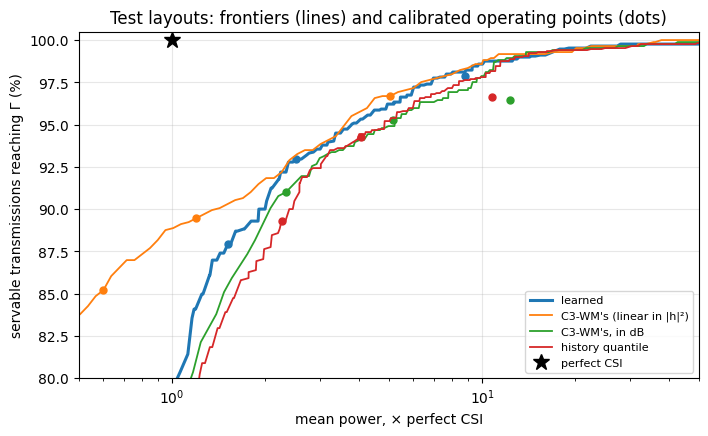

In [ ]:
plot_frontiers(results);

In [ ]:
network = simulate_network(saved, tmp, tmp, SEEDS['test'], fading='rayleigh')
analysis = results['predictors']['learned']['targets'][0.95]
print(f"{'':10s}{'reached Γ':>11s}{'power':>8s}{'withheld':>10s}{'error-free':>12s}{'wrong tokens':>14s}")
for name, r in (('network', network), ('analysis', analysis)):
    print(f"{name:10s}{100 * r['reliability']:10.1f}%{r['power']:7.1f}×{100 * r['withheld']:9.1f}%{100 * r['error_free']:11.1f}%"
          f"{100 * r['wrong_tokens']:13.2f}%")

            reached Γ   power  withheld  error-free  wrong tokens
network         93.0%    2.5×      0.4%       96.5%         0.84%
analysis        93.0%    2.5×      0.4%       96.5%         0.79%


At other target SNRs, with the same predictors (`κ` and `τ` chosen again for each `Γ`):

 Γ (dB)   g_min  servable                               90%: reached / power / error-free   95%: reached / power / error-free   99%: reached / power / error-free
      4   -100    100.0%  learned                            88.1%    1.5×   79.1%            93.3%    2.8×   88.1%            97.9%    8.7×   96.4%   
                           C3-WM's (linear in |h|²)           85.1%    0.5×   79.9%            89.4%    1.0×   86.3%            96.6%    4.4×   93.7%   
                           C3-WM's, in dB                     90.9%    2.0×   82.8%            95.3%    4.8×   92.7%            97.3%   17.4×   96.5%   
                           history quantile                   89.4%    2.2×   82.1%            95.0%    4.6×   91.7%            97.8%   13.7×   96.5%   
                           perfect CSI                       100.0%    1.0×    0.7%           100.0%    1.0×    0.7%           100.0%    1.0×    0.7%   
      7    -97    100.0%  learned                            88.1%    1.5×

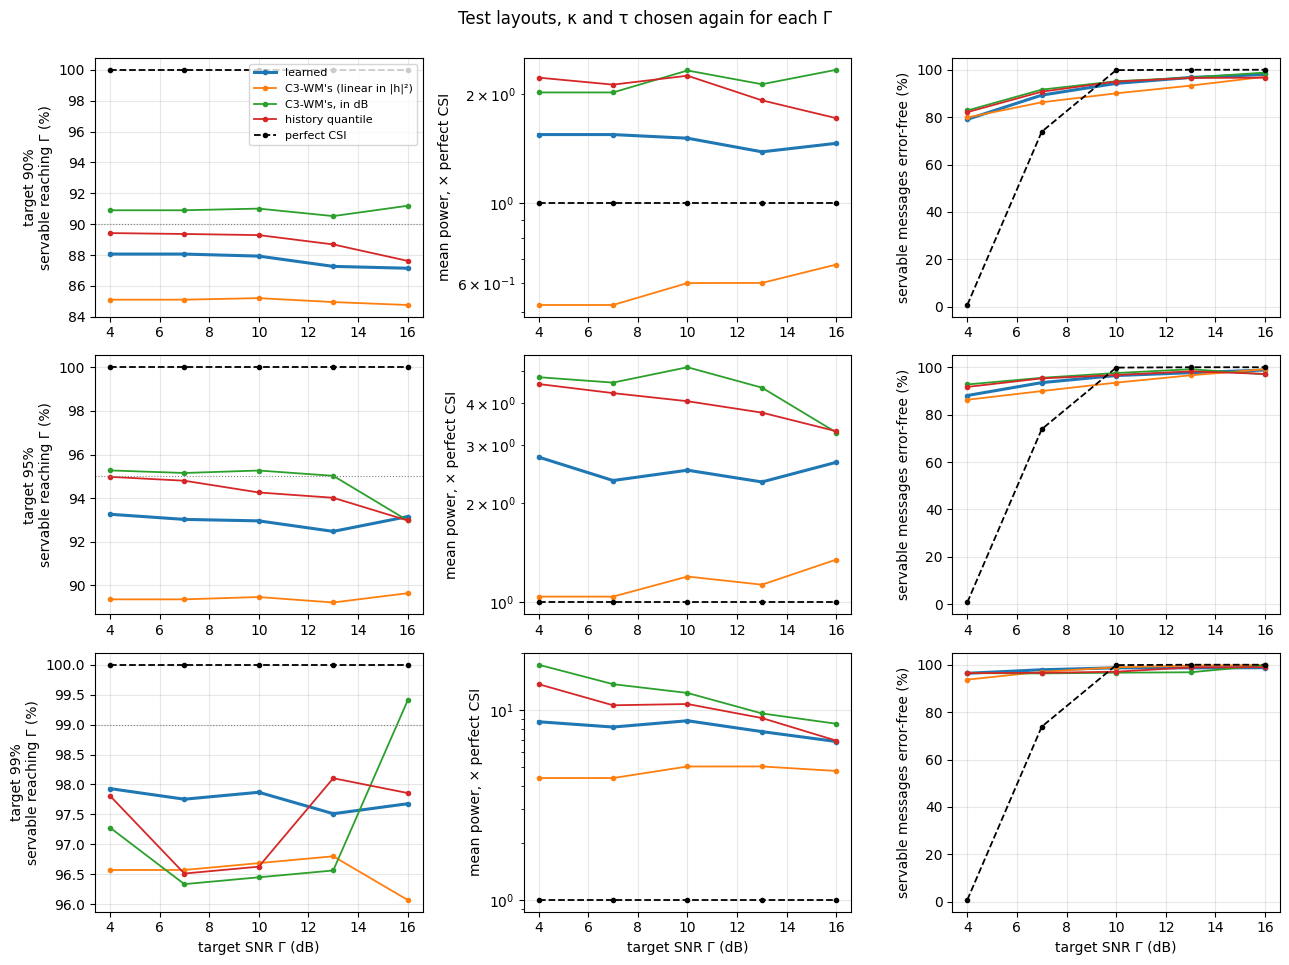

In [ ]:
print(snr_summary(results['snr']))
plot_snr(results['snr']);

A higher `Γ` raises the weakest servable gain `g_min = Γσ²/ρ_max` (fewer transmissions are servable), and makes the
messages arriving at `Γ` cleaner: perfect CSI's error-free share goes from many corrupted messages at low `Γ` to
nearly all clean at high `Γ`. The reliability and power at a `Γ` are those of a budget with the same `g_min`.

With so few calibration layouts, the target is missed by a few points on new layouts: the margin is chosen to just
reach it on the calibration layouts, which say little about the next one. More calibration layouts narrow the gap (in
comm-core's example *Power control on new layouts*, 6 layouts of a 9 × 9 FindGoal landed within 0.7 points of it), and
`slack` (calibrating for a slightly higher target) covers what remains.

In [ ]:
learned, paper = results['predictors']['learned'], results['predictors']["C3-WM's (linear in |h|²)"]
assert 0.85 < learned['prediction']['coverage'] <= 1                       # a low quantile: it rarely overestimates
assert learned['targets'][0.95]['reliability'] > 0.9
assert results['predictors']['perfect CSI']['targets'][0.95]['power'] <= 1.0001
assert abs(network['reliability'] - analysis['reliability']) < 0.005   # the same channels (a gain at the threshold may round apart)
assert abs(network['power'] - analysis['power']) < 0.01 * analysis['power']
assert abs(network['error_free'] - analysis['error_free']) < 0.03       # the bits' errors: random
sweep = results['snr']
assert sweep[10.0]['predictors'] == {n: r['targets'] for n, r in results['predictors'].items()}   # at the saved Γ: the same
assert np.all(np.diff([r['servable'] for r in sweep.values()]) <= 0)        # higher Γ: fewer servable transmissions
clean = [r['predictors']['perfect CSI'][0.95]['error_free'] for r in sweep.values()]
assert np.all(np.diff(clean) >= 0) and clean[-1] > 0.99                     # at exactly Γ: cleaner as Γ rises